## Imports and Paths

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 80)

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# DATASET_NAME = "ml-latest-small"
# DATASET_NAME = "ml-1m"
DATASET_NAME = "ml-latest"

RAW_DIR = PROJECT_ROOT / "data" / DATASET_NAME

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET_NAME)
print("Raw dir:", RAW_DIR)

Project root: c:\Users\Labea.DESKTOP-6B3LI5E\OneDrive\Dokumente\GitHub\Data-Lab
Dataset: ml-latest
Raw dir: c:\Users\Labea.DESKTOP-6B3LI5E\OneDrive\Dokumente\GitHub\Data-Lab\data\ml-latest


In [3]:
def load_movielens_raw(dataset_name, raw_dir):
    if dataset_name == "ml-1m":
        ratings = pd.read_csv(
            raw_dir / "ratings.dat",
            sep="::",
            names=["userId", "movieId", "rating", "timestamp"],
            engine="python",
            encoding="latin-1",
        )

        movies = pd.read_csv(
            raw_dir / "movies.dat",
            sep="::",
            names=["movieId", "title", "genres"],
            engine="python",
            encoding="latin-1",
        )

    else:
        ratings = pd.read_csv(raw_dir / "ratings.csv")
        movies = pd.read_csv(raw_dir / "movies.csv")

    return ratings, movies

In [4]:
ratings, movies = load_movielens_raw(DATASET_NAME, RAW_DIR)

print("Ratings shape:", ratings.shape)
display(ratings.head())
display(ratings.describe())

print("Movies shape:", movies.shape)
display(movies.head())

Ratings shape: (33832162, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119


,userId,movieId,rating,timestamp
count,3.383216e+07,3.383216e+07,3.383216e+07,3.383216e+07
mean,1.654380e+05,2.831348e+04,3.542540e+00,1.269362e+09
std,9.534122e+04,4.992865e+04,1.063959e+00,2.541023e+08
min,1.000000e+00,1.000000e+00,5.000000e-01,7.896520e+08
25%,8.295300e+04,1.219000e+03,3.000000e+00,1.046718e+09
50%,1.661290e+05,3.263000e+03,4.000000e+00,1.264740e+09
75%,2.474500e+05,4.049100e+04,4.000000e+00,1.496919e+09
max,3.309750e+05,2.889830e+05,5.000000e+00,1.689843e+09


Movies shape: (86537, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Missing values and duplicates

In [5]:
print("Missing values in ratings:")
display(ratings.isna().sum()) #ratings.isna creates a matrix of the same size as ratings with True/False values

print("Missing values in movies:")
display(movies.isna().sum())

print("Duplicate rows in ratings:", ratings.duplicated().sum()) #ratings.duplicated returns True/False value for each row
print("Duplicate rows in movies:", movies.duplicated().sum())

Missing values in ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in movies:


movieId    0
title      0
genres     0
dtype: int64

Duplicate rows in ratings: 0
Duplicate rows in movies: 0


## Ratings distribution

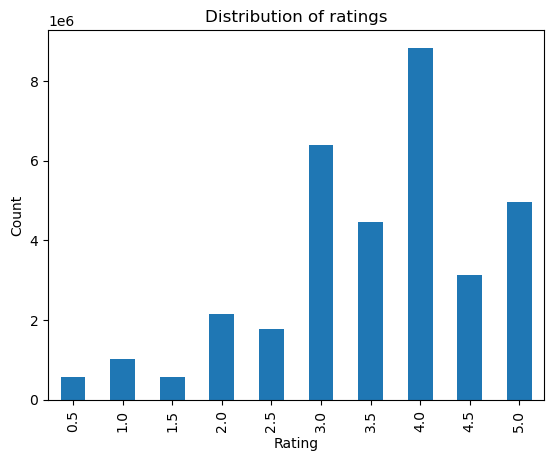

rating
4.0    8835955
3.0    6400664
5.0    4957902
3.5    4465001
4.5    3123055
2.0    2146492
2.5    1760733
1.0    1013645
0.5     566306
1.5     562409
Name: count, dtype: int64


In [6]:
ratings["rating"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Distribution of ratings")
plt.show()

print(ratings["rating"].value_counts())

## Number of users and movies

We see that there are 18 movies that are NOT rated.

In [7]:
n_users = ratings["userId"].nunique()
n_movies_rated = ratings["movieId"].nunique()
n_movies_total = movies["movieId"].nunique()

print("Number of users:", n_users)
print("Number of rated movies:", n_movies_rated)
print("Number of movies in movies.csv:", n_movies_total)

Number of users: 330975
Number of rated movies: 83239
Number of movies in movies.csv: 86537


MovieIDs are not sequential:

In [8]:
movie_ids = sorted(movies["movieId"].unique())

missing_movie_ids = set(range(min(movie_ids), max(movie_ids) + 1)) - set(movie_ids)

print("Min movieId:", min(movie_ids))
print("Max movieId:", max(movie_ids))
print("Number of existing movieIds:", len(movie_ids))
print("Number of missing movieIds:", len(missing_movie_ids))

print(sorted(list(missing_movie_ids))[:20])

Min movieId: 1
Max movieId: 288983
Number of existing movieIds: 86537
Number of missing movieIds: 202446
[91, 221, 291, 323, 545, 557, 578, 622, 624, 646, 669, 677, 686, 689, 740, 811, 817, 863, 883, 888]


## Sparsity of the user-item matrix

In [9]:
n_ratings = len(ratings)
possible_ratings = n_users * n_movies_rated

sparsity = 1 - n_ratings / possible_ratings

print("Number of ratings:", n_ratings)
print("Possible user-movie pairs:", possible_ratings)
print("Sparsity:", sparsity)

Number of ratings: 33832162
Possible user-movie pairs: 27550028025
Sparsity: 0.9987719735903972


## Most rated movies

In [10]:
most_rated_movies = (
    ratings
    .groupby("movieId")
    .size()
    .reset_index(name="num_ratings")
    .merge(movies, on="movieId")
    .sort_values("num_ratings", ascending=False)
)

display(most_rated_movies.head(10))
display(ratings.groupby("movieId").head(100))

,movieId,num_ratings,title,genres
314,318,122296,"Shawshank Redemption, The (1994)",Crime|Drama
351,356,113581,Forrest Gump (1994),Comedy|Drama|Romance|War
292,296,108756,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
2480,2571,107056,"Matrix, The (1999)",Action|Sci-Fi|Thriller
585,593,101802,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
257,260,97202,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
2867,2959,86207,Fight Club (1999),Action|Crime|Drama|Thriller
522,527,84232,Schindler's List (1993),Drama|War
475,480,83026,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
1166,1196,80200,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi


,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119
...,...,...,...,...
33829875,330949,60198,4.0,1643057671
33829986,330949,165471,2.5,1621964233
33830371,330957,4180,3.0,1039360531
33831032,330964,25908,1.5,1649131162
